     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


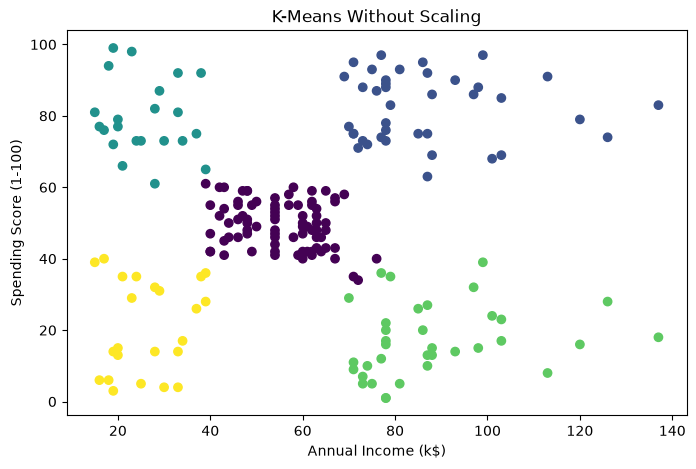

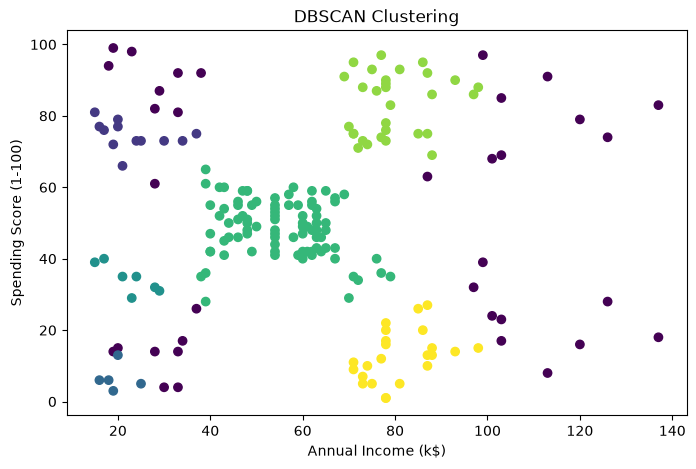

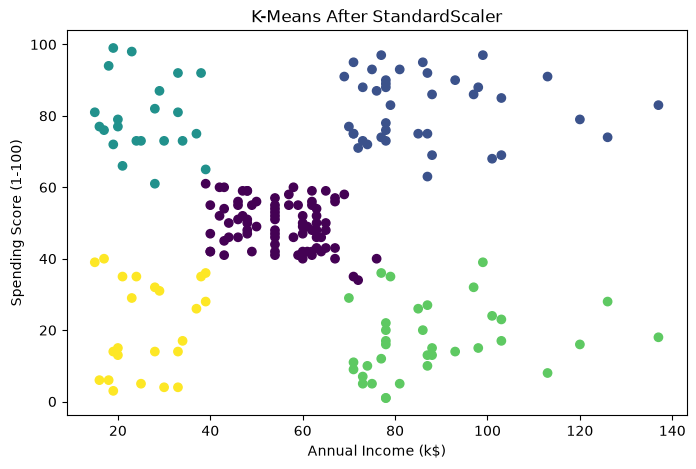

Comparison of Original and Scaled Clusters:
KMeans_Scaled     0   1   2   3   4
KMeans_Original                    
0                81   0   0   0   0
1                 0  39   0   0   0
2                 0   0  22   0   0
3                 0   0   0  35   0
4                 0   0   0   0  23

Original clusters: 5
Scaled clusters: 5
Scaling can change cluster assignments because features are put on a similar scale.


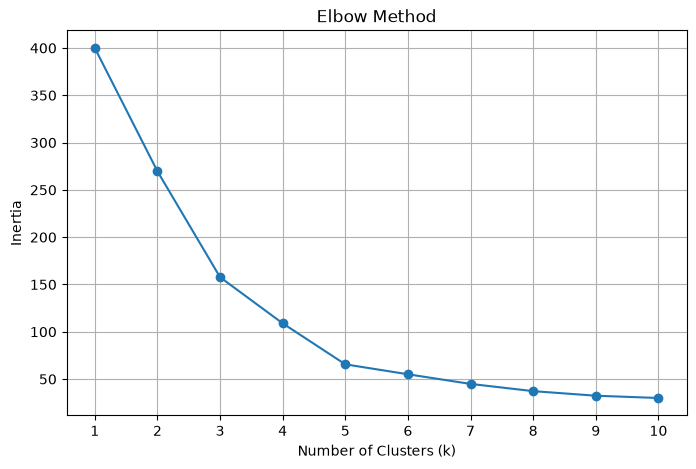

Average Annual Income and Spending Score for Each Cluster:
               Annual Income (k$)  Spending Score (1-100)
KMeans_Scaled                                            
0                       55.296296               49.518519
1                       86.538462               82.128205
2                       25.727273               79.363636
3                       88.200000               17.114286
4                       26.304348               20.913043


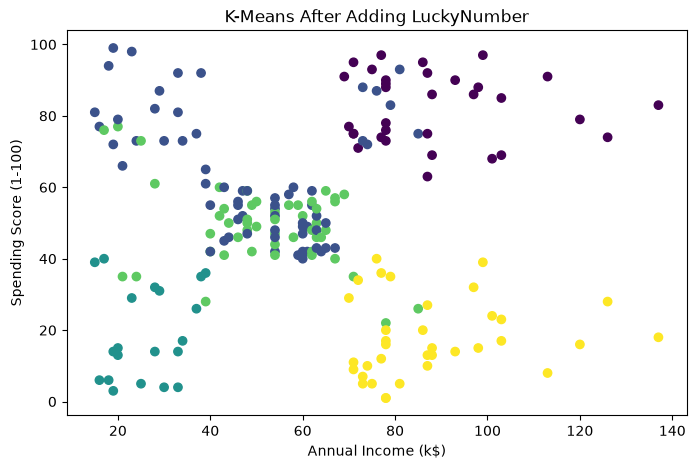


Cluster comparison after adding LuckyNumber:
KMeans_LuckyNumber   0   1   2   3   4
KMeans_Scaled                         
0                    0  39   0  40   2
1                   32   7   0   0   0
2                    0  18   0   4   0
3                    0   0   0   2  33
4                    0   0  20   3   0

LuckyNumber effect:
LuckyNumber is random and has no real relationship with customer behavior.
It can change cluster assignments by adding irrelevant information to the distance calculation.
This may make clusters less meaningful for understanding customer spending.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv("Mall_Customers.csv")
print(df)

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["KMeans_Original"] = kmeans.fit_predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df["KMeans_Original"], cmap="viridis")
plt.title("K-Means Without Scaling")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

dbscan = DBSCAN(eps=8, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df["DBSCAN_Cluster"], cmap="viridis")
plt.title("DBSCAN Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans_scaled = KMeans(n_clusters=5, random_state=42, n_init=10)
df["KMeans_Scaled"] = kmeans_scaled.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df["KMeans_Scaled"], cmap="viridis")
plt.title("K-Means After StandardScaler")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

comparison = pd.crosstab(df["KMeans_Original"], df["KMeans_Scaled"])
print("Comparison of Original and Scaled Clusters:")
print(comparison)

print("\nOriginal clusters:", df["KMeans_Original"].nunique())
print("Scaled clusters:", df["KMeans_Scaled"].nunique())
print("Scaling can change cluster assignments because features are put on a similar scale.")

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

cluster_summary = df.groupby("KMeans_Scaled")[["Annual Income (k$)", "Spending Score (1-100)"]].mean()
print("Average Annual Income and Spending Score for Each Cluster:")
print(cluster_summary)

np.random.seed(42)
df["LuckyNumber"] = np.random.randint(0, 101, size=len(df))

X_lucky = df[["Annual Income (k$)", "Spending Score (1-100)", "LuckyNumber"]]
X_lucky_scaled = StandardScaler().fit_transform(X_lucky)

kmeans_lucky = KMeans(n_clusters=5, random_state=42, n_init=10)
df["KMeans_LuckyNumber"] = kmeans_lucky.fit_predict(X_lucky_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df["KMeans_LuckyNumber"], cmap="viridis")
plt.title("K-Means After Adding LuckyNumber")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

print("\nCluster comparison after adding LuckyNumber:")
print(pd.crosstab(df["KMeans_Scaled"], df["KMeans_LuckyNumber"]))

print("\nLuckyNumber effect:")
print("LuckyNumber is random and has no real relationship with customer behavior.")
print("It can change cluster assignments by adding irrelevant information to the distance calculation.")
print("This may make clusters less meaningful for understanding customer spending.")